<img src=https://audiovisuales.icesi.edu.co/assets/custom/images/ICESI_logo_prin_descriptor_RGB_POSITIVO_0924.jpg width=200>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juanestebancg2806/ml3-time-series-forecasting/blob/main/sesion-01-promedios-moviles-suavizacion/ejercicio1_pronostico_ocupados.ipynb)

# Pronóstico del número de ocupados en las 13 principales ciudades de Colombia

**Aprendizaje Automático III — Universidad Icesi**

**Integrantes:** Juan Esteban Cardona, Daniel Velasco

Este notebook construye y evalúa modelos de pronóstico para el número mensual de ocupados, en miles de personas, de las 13 principales ciudades de Colombia, con el objetivo de pronosticar los próximos 6 meses. Se comparan promedios móviles con distintos tamaños de ventana y modelos de suavización exponencial con distintas configuraciones. Los modelos se eligen con una validación que respeta el orden temporal de los datos, y el modelo elegido se evalúa en una muestra de prueba con los 6 meses más recientes, que no se usa para tomar ninguna decisión de modelado. Finalmente, el modelo se ajusta con toda la serie para pronosticar de julio a diciembre de 2019.

## 1. Carga de paquetes

El notebook se desarrolló con Python 3.13 y las versiones de las librerías que se instalan en la celda siguiente. En un entorno que ya las tenga no hace falta instalarlas; en Google Colab, la celda de instalación se descomenta y se reinicia la sesión antes de continuar.

Después de cargar los paquetes se imprimen las versiones del entorno. Los modelos de suavización exponencial se estiman por máxima verosimilitud con un optimizador numérico, por lo que sus parámetros y errores pueden variar levemente entre sistemas operativos o procesadores, aun con las mismas versiones de las librerías.

In [1]:
# Instalación de las librerías con las versiones usadas en este notebook.
# Solo es necesaria en Google Colab o en un entorno que no las tenga instaladas:
# quitar el comentario de la línea %pip y, en Colab, reiniciar la sesión después
# de instalar (Entorno de ejecución > Reiniciar sesión) para que se carguen las
# versiones nuevas. Requiere Python 3.12 o superior.

# %pip install pandas==3.1.1 numpy==2.5.4 matplotlib==3.11.2 statsmodels==0.15.0 scikit-learn==1.9.1 scipy==1.18.1 openpyxl==3.1.5

In [2]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose          # descomposición (solo para describir la serie)
from statsmodels.tsa.exponential_smoothing.ets import ETSModel   # suavización exponencial (SES, Holt, Holt-Winters)
from sklearn.model_selection import TimeSeriesSplit              # validación con origen móvil
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error

In [3]:
# Versiones del entorno de ejecución, para poder reproducir los resultados
import platform
import sys

import matplotlib
import openpyxl
import scipy
import sklearn
import statsmodels

print(f"{'Python':<14}{sys.version.split()[0]}")
print(f"{'Plataforma':<14}{platform.platform()}")
for nombre_libreria, modulo in [
    ("pandas", pd),
    ("numpy", np),
    ("matplotlib", matplotlib),
    ("statsmodels", statsmodels),
    ("scikit-learn", sklearn),
    ("scipy", scipy),
    ("openpyxl", openpyxl),
]:
    print(f"{nombre_libreria:<14}{modulo.__version__}")

Python        3.13.9
Plataforma    macOS-27.0.1-arm64-arm-64bit-Mach-O
pandas        3.1.1
numpy         2.5.4
matplotlib    3.11.2
statsmodels   0.15.0
scikit-learn  1.9.1
scipy         1.18.1
openpyxl      3.1.5


## 2. Carga y exploración de los datos

Los datos provienen del archivo `datosEmpleo.xlsx`, que contiene series mensuales del mercado laboral de las 13 principales ciudades de Colombia. Para este ejercicio se usa la columna `Ocupados`, que corresponde al número de ocupados en miles de personas. Antes de construir los modelos, se revisa el periodo cubierto, si hay valores faltantes y el comportamiento general de la serie, para identificar su tendencia y su estacionalidad.

Observaciones: 222
Periodo: 2001-01 a 2019-06
Valores faltantes: 0
count      222.0
mean      9160.9
std       1295.5
min       6923.6
25%       7971.1
50%       9139.1
75%      10458.5
max      11037.2
Name: Ocupados, dtype: float64


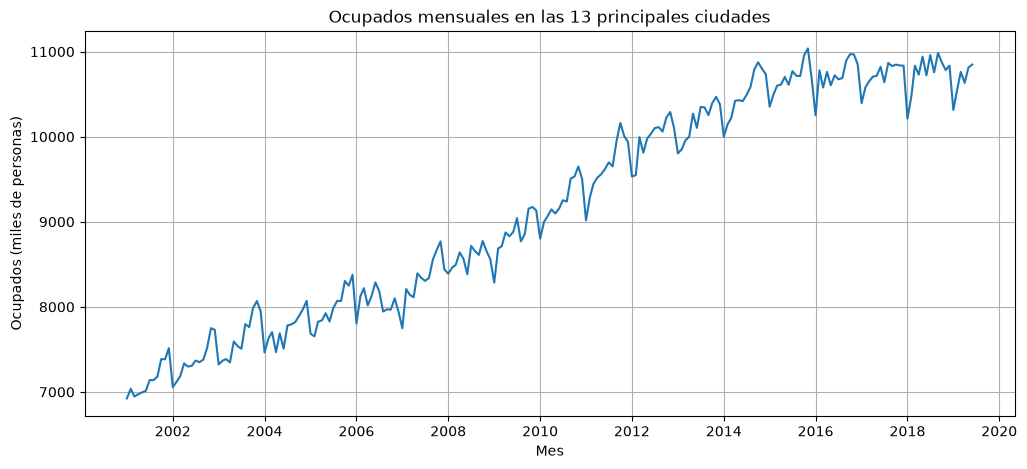

In [4]:
# Carga de datos: la columna "mes" se usa como índice de fechas
data = pd.read_excel(
    "https://raw.githubusercontent.com/dagudelo30/Aprendizaje-automatico-III/main/Clase_1/datosEmpleo.xlsx",
    index_col="mes",
    parse_dates=True,
)

# Serie de ocupados (miles de personas).
# asfreq("MS") declara la frecuencia mensual (inicio de mes): si faltara algún mes,
# aparecería como valor faltante, y además evita la advertencia de frecuencia de statsmodels.
ocupados = data["Ocupados"].asfreq("MS")

print("Observaciones:", len(ocupados))
print("Periodo:", ocupados.index.min().strftime("%Y-%m"), "a", ocupados.index.max().strftime("%Y-%m"))
print("Valores faltantes:", ocupados.isna().sum())
print(ocupados.describe().round(1))

# Gráfica de la serie completa
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados)
ax.set_title("Ocupados mensuales en las 13 principales ciudades")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.grid()
plt.show()

### Lectura de la serie

La serie tiene 222 observaciones mensuales, de enero de 2001 a junio de 2019, sin valores faltantes. El número de ocupados va de un mínimo de 6,924 mil personas a un máximo de 11,037 mil, con una media de 9,161 mil.

- **Tendencia:** la serie crece de forma casi lineal entre 2001 y 2014, de cerca de 7 millones a cerca de 10.4 millones de ocupados. Desde 2015 el crecimiento se detiene y la serie se mantiene entre 10.2 y 11 millones. La tendencia, por lo tanto, no es constante: cambia de pendiente en los últimos años.
- **Estacionalidad:** todos los años se repite el mismo patrón. Los ocupados alcanzan sus valores más altos en el último trimestre del año y caen bruscamente en enero, para luego recuperarse durante los meses siguientes. Este patrón coincide con el de la tasa de desempleo, que sube cada enero, y es compatible con la terminación de empleos temporales de fin de año, aunque los datos no permiten verificar esa causa.
- **Tamaño de la oscilación:** en la gráfica, la caída de enero parece hacerse más profunda a medida que aumenta el nivel de la serie. Esto sugiere que el efecto estacional podría ser proporcional al nivel, es decir, multiplicativo, algo que se revisará con los datos de entrenamiento.
- **Componente irregular:** además de la tendencia y la estacionalidad, la serie presenta fluctuaciones de un mes a otro sin un patrón claro.

Estas características orientan la elección de los modelos. Los promedios móviles y la suavización exponencial simple no capturan la tendencia ni la estacionalidad, por lo que sirven como referencia. Los modelos de Holt-Winters sí pueden capturar ambas, pero el cambio de pendiente de los últimos años hace necesario comparar configuraciones con y sin tendencia.

## 3. Partición de entrenamiento y prueba

Como el objetivo es pronosticar los próximos 6 meses, los últimos 6 meses de la serie se reservan como muestra de prueba: de enero a junio de 2019. Así, la evaluación final mide el desempeño de los modelos en el mismo horizonte en el que se usarán. El resto de la serie, de enero de 2001 a diciembre de 2018, forma la muestra de entrenamiento.

La partición respeta el orden temporal: todos los datos de entrenamiento son anteriores a los de prueba. Además, la muestra de prueba no se usa para tomar ninguna decisión de modelado, como elegir el tamaño de la ventana o la configuración de la suavización exponencial. Esas decisiones se toman solo con el entrenamiento, para que el error en la prueba sea una estimación honesta del desempeño del modelo con datos que no ha visto.

Entrenamiento: 2001-01 a 2018-12 (216 meses)
Prueba:        2019-01 a 2019-06 (6 meses)


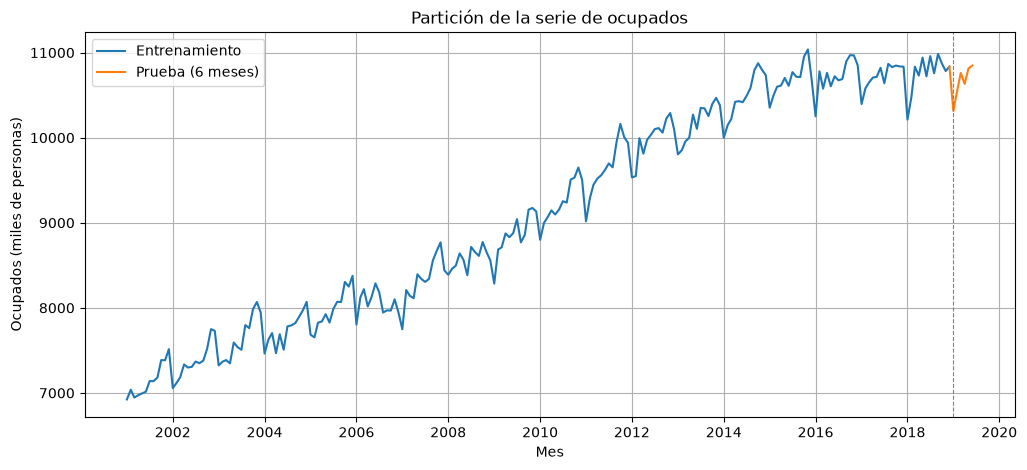

In [5]:
# Horizonte de pronóstico: 6 meses
horizonte = 6

# Partición temporal: los últimos 6 meses se reservan como prueba
train = ocupados.iloc[:-horizonte]
test = ocupados.iloc[-horizonte:]

print("Entrenamiento:", train.index.min().strftime("%Y-%m"), "a", train.index.max().strftime("%Y-%m"), f"({len(train)} meses)")
print("Prueba:       ", test.index.min().strftime("%Y-%m"), "a", test.index.max().strftime("%Y-%m"), f"({len(test)} meses)")

# Gráfica de la partición. La línea de prueba se dibuja desde el último mes de
# entrenamiento solo para que la gráfica se vea continua; los datos no cambian.
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train, label="Entrenamiento")
ax.plot(pd.concat([train.iloc[-1:], test]), label="Prueba (6 meses)", color="C1")
ax.axvline(test.index[0], color="gray", linestyle="--", linewidth=0.8)
ax.set_title("Partición de la serie de ocupados")
ax.set_xlabel("Mes")
ax.set_ylabel("Ocupados (miles de personas)")
ax.legend()
ax.grid()
plt.show()

La muestra de entrenamiento tiene 216 meses, de enero de 2001 a diciembre de 2018, y la de prueba 6 meses, de enero a junio de 2019. La prueba comienza con la caída estacional de enero y continúa con la recuperación de los meses siguientes, de modo que permite evaluar si los modelos capturan el patrón estacional de la serie y no solo su nivel.

## 4. Componentes de la serie y tipo de estacionalidad

Los modelos de Holt-Winters pueden suponer una estacionalidad aditiva, donde el efecto de cada mes es una cantidad fija de ocupados, o multiplicativa, donde el efecto es un porcentaje del nivel. Para orientar esa elección, la serie de entrenamiento se descompone con ambos supuestos y se comparan sus residuos: el supuesto adecuado es el que deja un residuo sin patrón. Se usa solo el entrenamiento para que la decisión no dependa de la muestra de prueba.

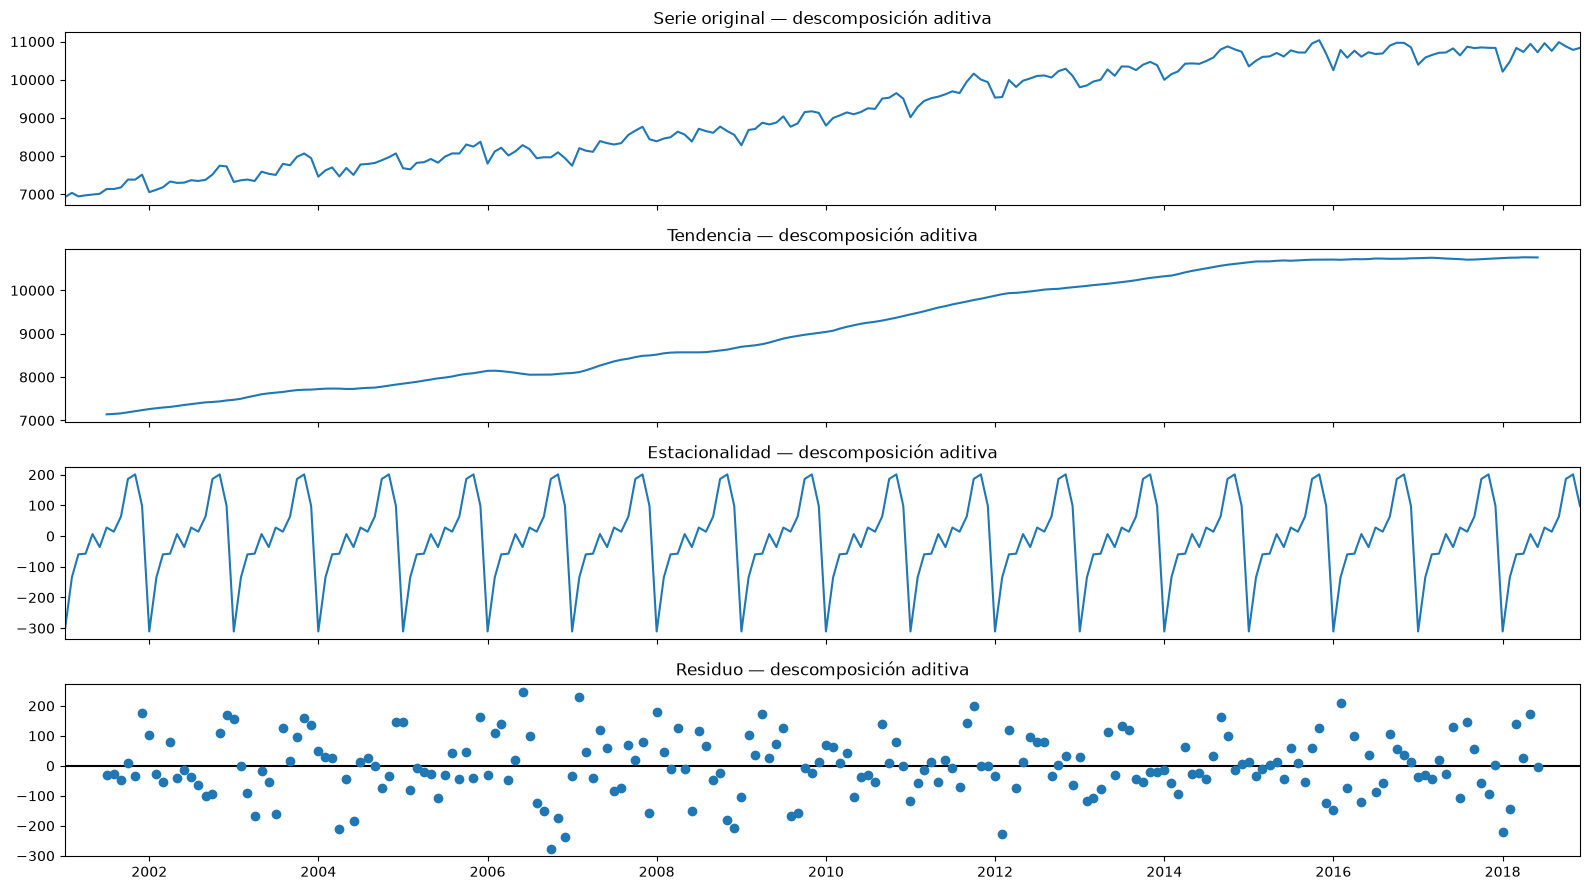

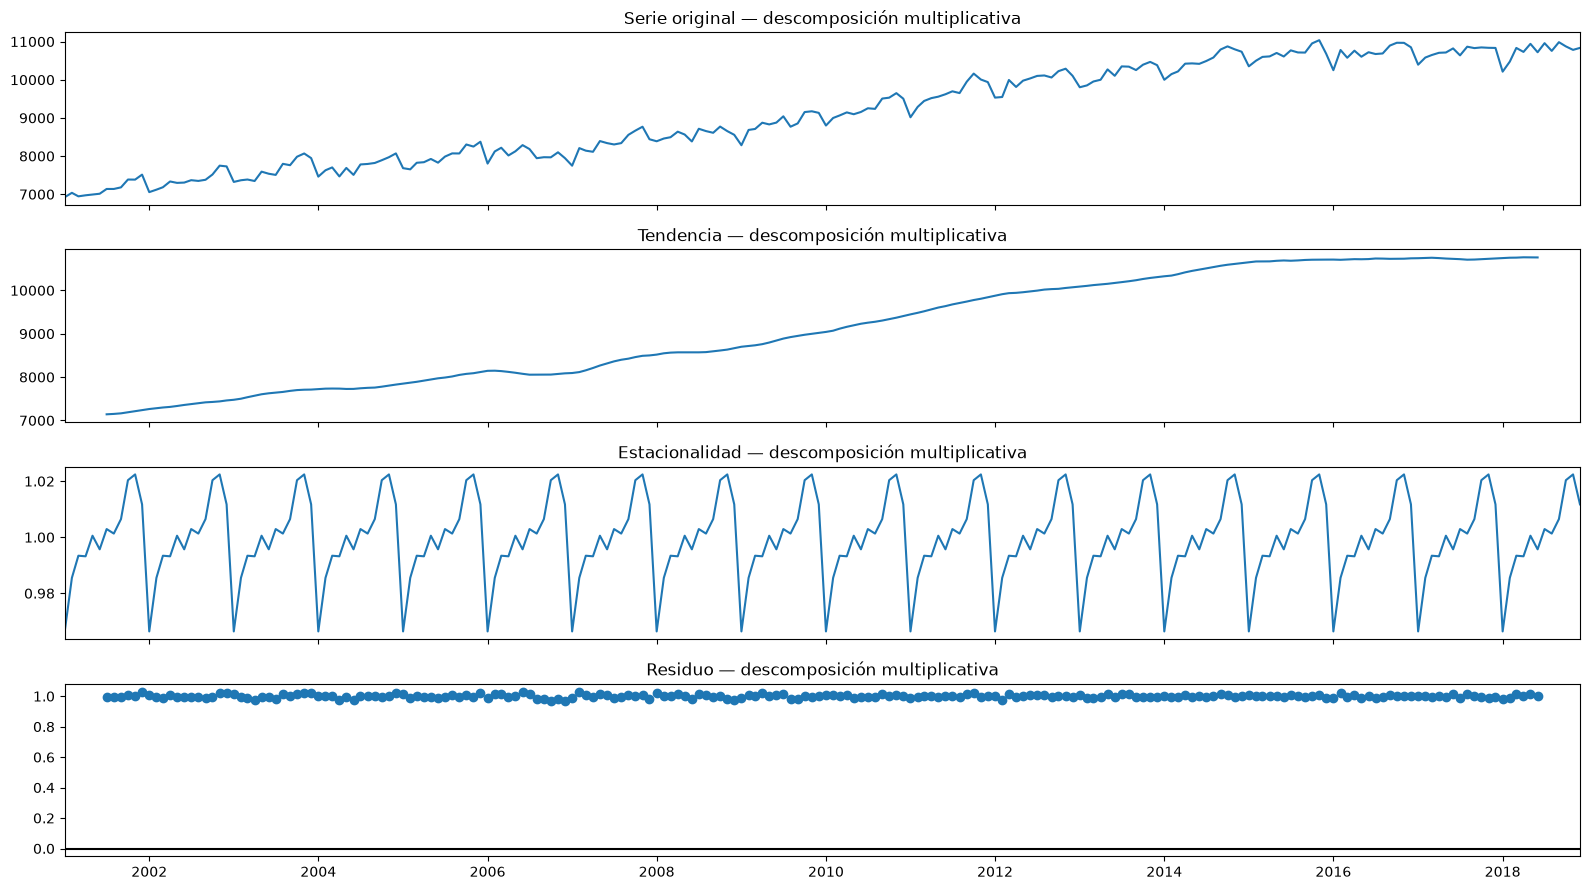

     Aditivo (miles de personas)  Multiplicativo (factor)
Ene                     -310.479                    0.966
Feb                     -134.241                    0.986
Mar                      -59.495                    0.993
Abr                      -57.295                    0.993
May                        6.527                    1.001
Jun                      -35.769                    0.996
Jul                       27.708                    1.003
Ago                       14.336                    1.001
Sep                       63.805                    1.006
Oct                      185.986                    1.020
Nov                      200.802                    1.022
Dic                       98.116                    1.012


In [6]:
# Descomposición clásica del entrenamiento con ambos supuestos
desc_aditiva = seasonal_decompose(train, model="additive")
desc_multiplicativa = seasonal_decompose(train, model="multiplicative")

# Gráficas de ambas descomposiciones, con títulos en español
titulos = ["Serie original", "Tendencia", "Estacionalidad", "Residuo"]
for desc, nombre in [(desc_aditiva, "aditiva"), (desc_multiplicativa, "multiplicativa")]:
    fig = desc.plot()
    fig.set_size_inches((16, 9))
    for eje, titulo in zip(fig.axes, titulos):
        eje.set_title(f"{titulo} — descomposición {nombre}")
        eje.set_ylabel("")
    fig.tight_layout()
    plt.show()

# Efecto estacional estimado para cada mes con ambos supuestos
# (el entrenamiento empieza en enero, así que las primeras 12 filas van de enero a diciembre)
nombres_meses = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
efectos_estacionales = pd.DataFrame({
    "Aditivo (miles de personas)": desc_aditiva.seasonal.iloc[:12].values,
    "Multiplicativo (factor)": desc_multiplicativa.seasonal.iloc[:12].values,
}, index=nombres_meses)
print(efectos_estacionales.round(3))

### Componentes de la serie de entrenamiento

Las dos figuras muestran la descomposición de la serie de entrenamiento con cada supuesto. Cada una tiene cuatro paneles: la serie original, la tendencia, la estacionalidad y el residuo. Bajo el supuesto aditivo, la serie es la suma de las tres piezas (tendencia + estacionalidad + residuo); bajo el multiplicativo, es su producto (tendencia × estacionalidad × residuo).

**Serie original y tendencia.** Ambas descomposiciones parten de la misma serie y estiman la misma tendencia, porque las dos la calculan con el mismo promedio móvil centrado de 12 meses. Por esa misma razón, la tendencia no está disponible en los primeros ni en los últimos 6 meses del entrenamiento. Los ocupados crecen de cerca de 7,150 mil a mediados de 2001 a cerca de 10,700 mil en 2015, con una breve pausa entre 2006 y 2007, y desde 2015 se mantienen prácticamente estables hasta 2018.

**Estacionalidad.** Ambas descomposiciones encuentran el mismo patrón, repetido de forma idéntica todos los años, porque la descomposición clásica supone un único patrón estacional. Lo que cambia es la forma de medirlo:

| Mes | Efecto aditivo (miles de personas) | Efecto multiplicativo |
|---|---|---|
| Enero | -310 | 0.966 (3.4 % por debajo de la tendencia) |
| Febrero | -134 | 0.986 (1.4 % por debajo) |
| Octubre | +186 | 1.020 (2.0 % por encima) |
| Noviembre | +201 | 1.022 (2.2 % por encima) |
| Diciembre | +98 | 1.012 (1.2 % por encima) |

En el supuesto aditivo, el efecto es una cantidad fija de personas que se suma a la tendencia. En el multiplicativo, es un factor que multiplica la tendencia: un factor de 1.022 equivale a quedar 2.2 % por encima, y uno de 0.966, a quedar 3.4 % por debajo. Por eso, en el multiplicativo el efecto en personas crece con el nivel de la serie. Por ejemplo, la caída de enero sería de 310 mil personas en cualquier año con el supuesto aditivo, mientras que con el multiplicativo sería de cerca de 245 mil cuando la tendencia está en 7,200 mil y de cerca de 364 mil cuando está en 10,700 mil.

Con ambos supuestos, los ocupados caen con fuerza en enero, se recuperan gradualmente entre febrero y abril, se mantienen cerca de la tendencia a mitad de año y alcanzan sus valores más altos en octubre y noviembre.

**Residuo.** En la descomposición aditiva, el residuo oscila alrededor de 0, casi siempre entre -250 y 250 mil personas, sin una forma que se repita a simple vista, aunque con algunos valores más alejados entre 2006 y 2007, que coinciden con la pausa de la tendencia. En la descomposición multiplicativa, el residuo no puede evaluarse en la gráfica: la función dibuja la línea de referencia en 0, aunque este residuo gira alrededor de 1, así que los valores quedan comprimidos en una franja casi plana. Además, un patrón que afecte solo a un mes puede quedar escondido entre los demás meses. Por eso, en la siguiente celda se grafican ambos residuos en su propia escala y se resaltan los eneros, el mes con el mayor efecto estacional.

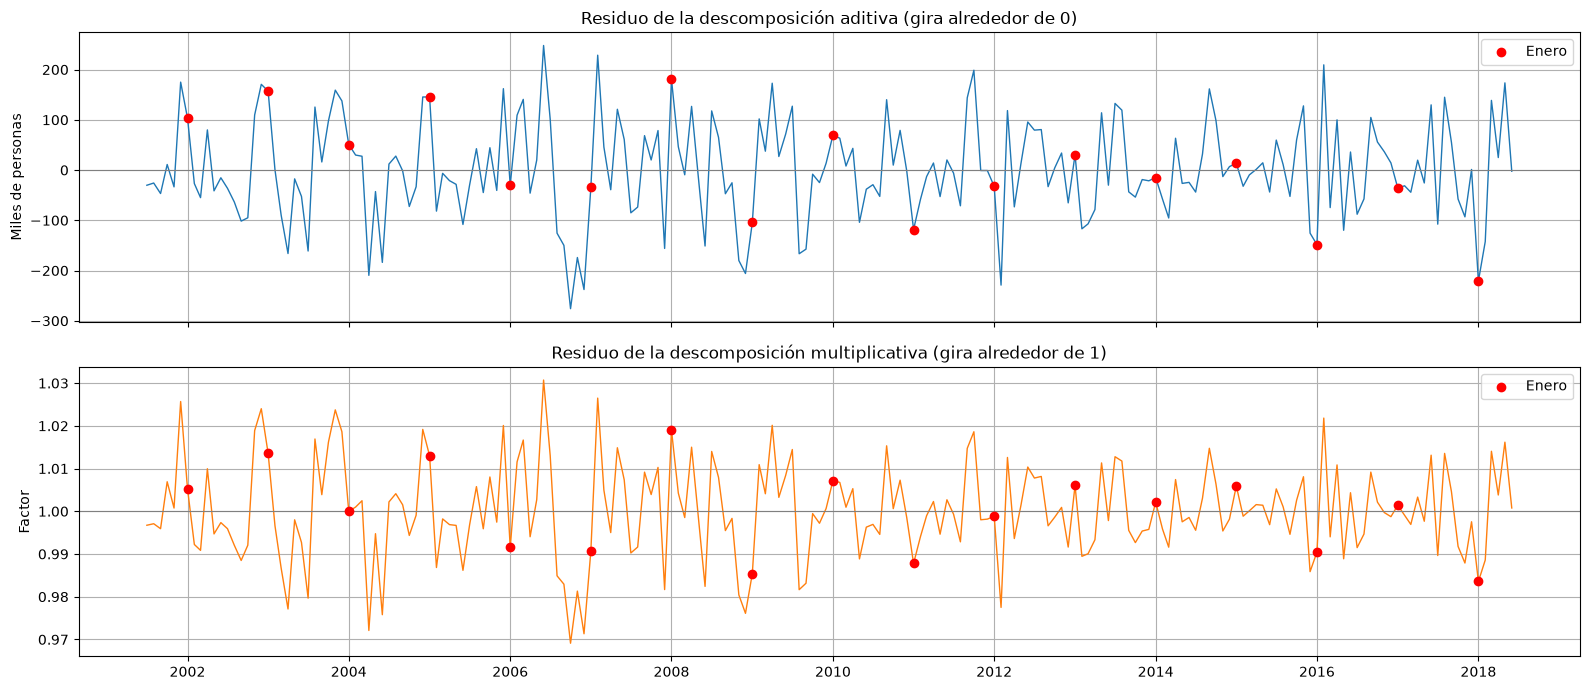

In [7]:
# Comparación de los residuos de ambas descomposiciones en su propia escala.
# Se resalta enero, el mes con el mayor efecto estacional: si el supuesto es correcto,
# sus residuos no deben quedar sistemáticamente arriba o abajo de la referencia.
es_enero = train.index.month == 1
fig, axes = plt.subplots(2, 1, figsize=(16, 7), sharex=True)

axes[0].plot(desc_aditiva.resid, color="C0", linewidth=1)
axes[0].scatter(train.index[es_enero], desc_aditiva.resid[es_enero], color="red", zorder=3, label="Enero")
axes[0].axhline(0, color="gray", linewidth=0.8)
axes[0].set_title("Residuo de la descomposición aditiva (gira alrededor de 0)")
axes[0].set_ylabel("Miles de personas")
axes[0].legend()
axes[0].grid()

axes[1].plot(desc_multiplicativa.resid, color="C1", linewidth=1)
axes[1].scatter(train.index[es_enero], desc_multiplicativa.resid[es_enero], color="red", zorder=3, label="Enero")
axes[1].axhline(1, color="gray", linewidth=0.8)
axes[1].set_title("Residuo de la descomposición multiplicativa (gira alrededor de 1)")
axes[1].set_ylabel("Factor")
axes[1].legend()
axes[1].grid()

fig.tight_layout()
plt.show()

In [8]:
# Tendencia, residuos y caída real de cada enero, para leer con precisión la gráfica anterior.
# La caída real es cuánto quedó enero por debajo de la tendencia en ese año.
eneros = pd.DataFrame({
    "Tendencia": desc_aditiva.trend[es_enero],
    "Residuo aditivo": desc_aditiva.resid[es_enero],
    "Residuo multiplicativo": desc_multiplicativa.resid[es_enero],
})
eneros["Caída real (miles)"] = eneros["Tendencia"] - train[es_enero]
eneros["Caída real (%)"] = 100 * eneros["Caída real (miles)"] / eneros["Tendencia"]

# Enero de 2001 no tiene tendencia (el promedio móvil centrado pierde los primeros 6 meses)
print(eneros.dropna().round(3))

            Tendencia  Residuo aditivo  Residuo multiplicativo  \
mes                                                              
2002-01-01   7263.377          103.436                   1.005   
2003-01-01   7476.767          157.169                   1.014   
2004-01-01   7722.007           50.852                   1.000   
2005-01-01   7849.145          145.386                   1.013   
2006-01-01   8144.433          -29.839                   0.992   
2007-01-01   8093.627          -34.342                   0.991   
2008-01-01   8518.405          180.830                   1.019   
2009-01-01   8699.738         -104.324                   0.985   
2010-01-01   9041.572           69.601                   1.007   
2011-01-01   9446.190         -118.360                   0.988   
2012-01-01   9875.534          -32.602                   0.999   
2013-01-01  10083.739           30.560                   1.006   
2014-01-01  10324.903          -14.868                   1.002   
2015-01-01

In [9]:
# Residuo multiplicativo expresado en miles para compararlo con el residuo aditivo.
# En el modelo multiplicativo Y = T * S * R, el desvío en miles es T * S * (R - 1).
factor_enero = desc_multiplicativa.seasonal[es_enero]

eneros["Residuo multiplicativo (miles)"] = (
    eneros["Tendencia"] * factor_enero * (eneros["Residuo multiplicativo"] - 1)
)

comparacion_residuos = eneros[["Residuo aditivo", "Residuo multiplicativo (miles)"]].dropna()
print(comparacion_residuos.round(1))

print("\nPromedio del valor absoluto del residuo de enero (miles):")
print(comparacion_residuos.abs().mean().round(1))

print("\nPromedio del residuo de enero por periodo (miles):")
print(pd.DataFrame({
    "2002-2005": comparacion_residuos.loc["2002":"2005"].mean(),
    "2016-2018": comparacion_residuos.loc["2016":"2018"].mean(),
}).round(1))

            Residuo aditivo  Residuo multiplicativo (miles)
mes                                                        
2002-01-01            103.4                            37.0
2003-01-01            157.2                            97.9
2004-01-01             50.9                            -0.2
2005-01-01            145.4                            98.6
2006-01-01            -29.8                           -66.7
2007-01-01            -34.3                           -72.9
2008-01-01            180.8                           156.5
2009-01-01           -104.3                          -122.5
2010-01-01             69.6                            62.9
2011-01-01           -118.4                          -111.5
2012-01-01            -32.6                           -11.3
2013-01-01             30.6                            58.8
2014-01-01            -14.9                            21.5
2015-01-01             13.7                            61.0
2016-01-01           -148.3             

### Elección del tipo de estacionalidad

Para decidir entre el supuesto aditivo y el multiplicativo se analizaron los eneros, porque enero es el mes con el mayor efecto estacional: la descomposición aditiva estima una caída fija de 310.5 mil personas frente a la tendencia, y la multiplicativa una caída de 3.4 % (factor de 0.966). Si el supuesto es correcto, los residuos de enero deberían oscilar alrededor de cero sin un patrón en el tiempo. Como los dos residuos están en unidades distintas, el multiplicativo se expresó en miles como $T_t \cdot S_t \cdot (R_t - 1)$, es decir, el valor esperado por el modelo multiplicado por el porcentaje en que se aleja de él.

| Residuo de enero (miles) | Aditivo | Multiplicativo |
|---|---|---|
| Promedio del valor absoluto, 2002-2018 | 87.7 | 74.3 |
| Promedio 2002-2005 | +114.2 | +58.3 |
| Promedio 2016-2018 | -135.0 | -85.0 |

Con el supuesto aditivo hay un sesgo claro. Entre 2002 y 2005, cuando la tendencia estaba entre 7 263 y 7 849 mil, la caída real de enero fue de 153 a 260 mil, menor que la estimada, y el residuo queda positivo. En 2016 y 2018, con una tendencia cercana a 10 700 mil, la caída real fue de 459 y 532 mil, mayor que la estimada, y el residuo queda negativo. Es decir, la caída de enero creció con el nivel de la serie, lo que contradice el supuesto aditivo de un efecto fijo en miles.

El supuesto multiplicativo reduce este sesgo, porque una caída en porcentaje se traduce en más personas cuando el nivel es mayor: el error promedio baja de 87.7 a 74.3 mil (cerca de 15 %) y los promedios por periodo se reducen a +58.3 y -85.0 mil. La mejora se concentra en los extremos del periodo, 2002-2005 y 2016-2018, donde el nivel está más lejos del promedio de la serie y los dos supuestos producen caídas más distintas. En cambio, en 2006, 2007, 2009, 2013, 2014 y 2015 el residuo multiplicativo es mayor que el aditivo.

Además, el sesgo conserva el mismo signo en ambos periodos. La caída de enero como porcentaje de la tendencia varía bastante de un año a otro, entre 1.5 % y 4.9 %, pero en promedio pasó de 2.6 % en 2002-2005 a 4.2 % en 2016-2018, es decir, creció incluso más que en proporción al nivel. Esto sugiere que el patrón estacional cambió con el tiempo, algo que la descomposición clásica no puede capturar porque supone el mismo efecto para todos los años.

Por lo tanto, el supuesto multiplicativo describe mejor la serie, pero la ventaja es moderada. En los modelos de Holt-Winters se evaluarán ambos tipos de estacionalidad y la elección final se hará con el error de pronóstico en la validación. Además, es deseable que el modelo pueda actualizar sus efectos estacionales con el tiempo, lo que en Holt-Winters controla el parámetro $\gamma$.

## 5. Esquema de validación y modelos de referencia

Para elegir entre modelos y configuraciones sin usar la muestra de prueba, se aplica una validación con origen móvil dentro del entrenamiento. Es la versión de la validación cruzada para series de tiempo: en lugar de partir los datos al azar, se definen varios cortes en el tiempo, y en cada uno el modelo se ajusta con los meses anteriores al corte y pronostica los 6 meses siguientes. Se usan 6 cortes, de modo que cada modelo se evalúa en 6 semestres distintos entre 2016 y 2018, y no depende de un solo periodo. En cada corte se calculan dos métricas:

- **RMSE** (raíz del error cuadrático medio), en miles de personas, que penaliza más los errores grandes.
- **MAPE** (error porcentual absoluto medio), en porcentaje del valor real, que permite leer el error en términos relativos.

El criterio principal de selección es el RMSE promedio de los 6 cortes, porque está en las mismas unidades de la serie y castiga con más fuerza los meses en que el pronóstico se aleja mucho del valor real. El MAPE promedio se usa como complemento, y entre los mejores modelos se revisa además en cuántos cortes cada uno supera al naive estacional, para que la elección no dependa de un solo semestre.

Como referencia se usan dos pronósticos ingenuos. El **naive** repite el último valor observado en los 6 meses, y el **naive estacional** repite el valor del mismo mes del año anterior. Un modelo solo aporta valor si mejora estas referencias.

In [10]:
# Validación con origen móvil dentro del entrenamiento (la muestra de prueba no se usa aquí).
# TimeSeriesSplit no mezcla los datos: cada corte ajusta con los meses anteriores
# y valida con los 6 meses siguientes. Por defecto la ventana de ajuste es expansiva
# (max_train_size=None), es decir, cada corte usa toda la historia disponible hasta ese punto.
n_cortes = 6
tscv = TimeSeriesSplit(n_splits=n_cortes, test_size=horizonte)

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    print(
        f"Corte {numero}: ajuste {train.index[idx_ajuste[0]]:%Y-%m} a {train.index[idx_ajuste[-1]]:%Y-%m} "
        f"({len(idx_ajuste)} meses) | validación {train.index[idx_validacion[0]]:%Y-%m} "
        f"a {train.index[idx_validacion[-1]]:%Y-%m}"
    )

Corte 1: ajuste 2001-01 a 2015-12 (180 meses) | validación 2016-01 a 2016-06
Corte 2: ajuste 2001-01 a 2016-06 (186 meses) | validación 2016-07 a 2016-12
Corte 3: ajuste 2001-01 a 2016-12 (192 meses) | validación 2017-01 a 2017-06
Corte 4: ajuste 2001-01 a 2017-06 (198 meses) | validación 2017-07 a 2017-12
Corte 5: ajuste 2001-01 a 2017-12 (204 meses) | validación 2018-01 a 2018-06
Corte 6: ajuste 2001-01 a 2018-06 (210 meses) | validación 2018-07 a 2018-12


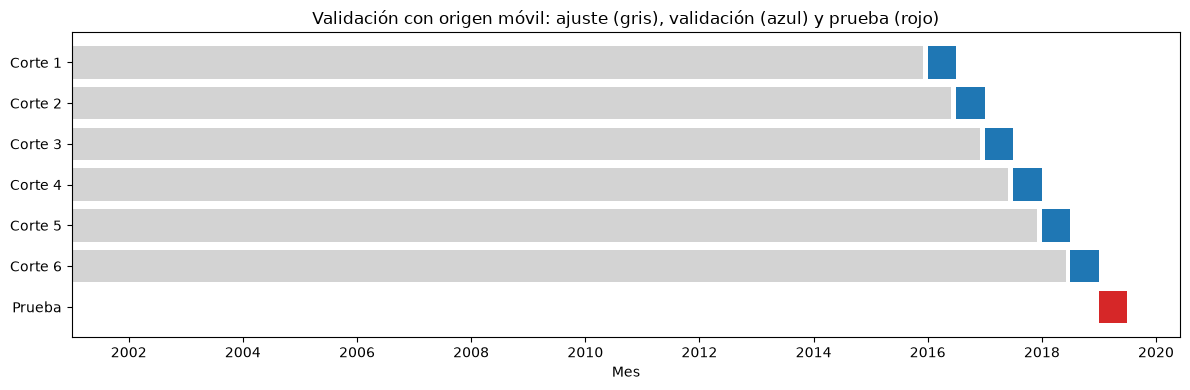

In [11]:
# Diagrama de los cortes de validación y de la muestra de prueba
fig, ax = plt.subplots(figsize=(12, 4))

for numero, (idx_ajuste, idx_validacion) in enumerate(tscv.split(train), start=1):
    inicio_ajuste, fin_ajuste = train.index[idx_ajuste[0]], train.index[idx_ajuste[-1]]
    inicio_validacion, fin_validacion = train.index[idx_validacion[0]], train.index[idx_validacion[-1]]
    # Barra gris: meses de ajuste; barra azul: meses de validación
    ax.barh(numero, fin_ajuste - inicio_ajuste, left=inicio_ajuste, color="lightgray")
    ax.barh(numero, fin_validacion - inicio_validacion + pd.Timedelta(days=30),
            left=inicio_validacion, color="C0")

# Muestra de prueba, reservada hasta el final
ax.barh(n_cortes + 1, test.index[-1] - test.index[0] + pd.Timedelta(days=30),
        left=test.index[0], color="C3")

ax.set_yticks(range(1, n_cortes + 2))
ax.set_yticklabels([f"Corte {numero}" for numero in range(1, n_cortes + 1)] + ["Prueba"])
ax.invert_yaxis()
ax.set_title("Validación con origen móvil: ajuste (gris), validación (azul) y prueba (rojo)")
ax.set_xlabel("Mes")
plt.tight_layout()
plt.show()

El diagrama muestra los 6 cortes de la validación. En cada uno, el modelo se ajusta con todos los meses desde enero de 2001 (gris) y se evalúa en los 6 meses siguientes (azul), de modo que los cortes cubren de forma consecutiva los semestres de 2016 a 2018. La muestra de prueba (rojo) queda por fuera de todos los cortes y solo se usa al final, para evaluar el modelo elegido.

In [12]:
def evaluar_validacion(funcion_pronostico, serie=train, cv=tscv):
    """Evalúa un método de pronóstico en cada corte de la validación con origen móvil.

    funcion_pronostico(serie_ajuste, h) debe devolver h pronósticos usando solo serie_ajuste.
    Devuelve una tabla con el RMSE (miles) y el MAPE (%) de cada corte.
    """
    filas = []
    for idx_ajuste, idx_validacion in cv.split(serie):
        serie_ajuste = serie.iloc[idx_ajuste]
        serie_validacion = serie.iloc[idx_validacion]
        pronostico = funcion_pronostico(serie_ajuste, len(serie_validacion))
        filas.append({
            "inicio_validacion": serie_validacion.index[0].strftime("%Y-%m"),
            "rmse": np.sqrt(mean_squared_error(serie_validacion, pronostico)),
            # sklearn devuelve el MAPE como fracción, por eso se multiplica por 100
            "mape": 100 * mean_absolute_percentage_error(serie_validacion, pronostico),
        })
    return pd.DataFrame(filas).set_index("inicio_validacion")


def pronostico_naive(serie_ajuste, h):
    """Repite el último valor observado en los h meses siguientes."""
    return np.repeat(serie_ajuste.iloc[-1], h)


def pronostico_naive_estacional(serie_ajuste, h, m=12):
    """Repite el valor del mismo mes del año anterior (válido para h <= m)."""
    return serie_ajuste.iloc[-m:].iloc[:h].values


# Resultados por corte de cada método; se irán agregando los demás modelos a este diccionario
validacion = {}
validacion["Naive"] = evaluar_validacion(pronostico_naive)
validacion["Naive estacional"] = evaluar_validacion(pronostico_naive_estacional)

for nombre, tabla in validacion.items():
    print(f"\n{nombre}")
    print(tabla.round(2))

resumen_validacion = pd.DataFrame({nombre: tabla.mean() for nombre, tabla in validacion.items()}).T
resumen_validacion.columns = ["RMSE promedio", "MAPE promedio (%)"]
print("\nResumen")
print(resumen_validacion.round(2))


Naive
                     rmse  mape
inicio_validacion              
2016-01            191.58  1.33
2016-07            169.33  1.34
2017-01            245.52  1.95
2017-07             77.88  0.45
2018-01            302.74  2.09
2018-07            167.46  1.33

Naive estacional
                     rmse  mape
inicio_validacion              
2016-01            149.37  1.19
2016-07            113.50  0.86
2017-01            122.75  1.07
2017-07            107.29  0.84
2018-01            153.32  1.29
2018-07            153.90  1.02

Resumen
                  RMSE promedio  MAPE promedio (%)
Naive                    192.42               1.41
Naive estacional         133.36               1.05


### Resultados de los modelos de referencia

Los 6 cortes validan semestres consecutivos entre enero de 2016 y diciembre de 2018, con un ajuste que va de 180 a 210 meses, y ninguno usa la muestra de prueba.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) |
|---|---|---|
| Naive | 192.42 | 1.41 |
| Naive estacional | 133.36 | 1.05 |

El naive estacional reduce el RMSE promedio en cerca de 31 % frente al naive. Como en 2016-2018 el nivel de la serie fue casi constante, la principal diferencia entre los dos métodos es que el naive estacional reproduce el patrón del calendario, lo que indica que capturar la estacionalidad es clave para pronosticar esta serie a 6 meses. El naive tiene sus mayores errores en los cortes que empiezan en enero (245.5 mil en 2017 y 302.7 mil en 2018), porque repite el valor de diciembre, que es de los más altos del año, en meses en que la serie cae. Solo supera al naive estacional en el corte de julio de 2017 (77.9 frente a 107.3 mil), cuando el valor de junio quedó cerca del nivel del segundo semestre. El naive estacional, en cambio, tiene un error más estable entre cortes (de 107.3 a 153.9 mil).

Hay que tener en cuenta que el naive estacional no incluye tendencia, y que en el periodo de validación la tendencia de la serie fue casi plana (alrededor de 10 700 mil entre 2016 y 2018), lo que lo favorece. Aun así, se toma como la referencia a superar: un modelo solo se considera útil si obtiene un RMSE promedio menor a 133.36 mil y un MAPE menor a 1.05 %.

## 6. Promedios móviles

El promedio móvil pronostica el siguiente mes como el promedio de los últimos $k$ valores observados:

$$\hat{y}_{t+1} = \frac{1}{k}\sum_{i=0}^{k-1} y_{t-i}$$

Para pronosticar 6 meses sin usar valores reales del periodo de validación, el pronóstico se hace de forma recursiva: cada valor pronosticado se agrega a la historia y entra en el promedio del mes siguiente. Por eso, después de unos pasos el pronóstico se estabiliza en un valor casi constante. El método no modela tendencia ni estacionalidad; el tamaño de la ventana solo controla cuánta historia reciente se promedia. Se evalúan ventanas de 2, 3, 4, 6 y 12 meses con los mismos cortes de validación que los modelos de referencia.

In [13]:
def pronostico_promedio_movil(serie_ajuste, h, k):
    """Pronóstico recursivo con promedio móvil de ventana k.

    Cada pronóstico es el promedio de los últimos k valores de la historia;
    luego se agrega a la historia para calcular el siguiente (no usa valores reales futuros).
    """
    historia = list(serie_ajuste.iloc[-k:])
    pronosticos = []
    for _ in range(h):
        siguiente = np.mean(historia[-k:])
        pronosticos.append(siguiente)
        historia.append(siguiente)
    return np.array(pronosticos)


ventanas = [2, 3, 4, 6, 12]

for k in ventanas:
    # lambda con k=k para fijar el valor de la ventana en cada iteración
    validacion[f"MA k={k}"] = evaluar_validacion(
        lambda serie_ajuste, h, k=k: pronostico_promedio_movil(serie_ajuste, h, k)
    )

resumen_validacion = pd.DataFrame({nombre: tabla.mean() for nombre, tabla in validacion.items()}).T
resumen_validacion.columns = ["RMSE promedio", "MAPE promedio (%)"]
print(resumen_validacion.round(2))

                  RMSE promedio  MAPE promedio (%)
Naive                    192.42               1.41
Naive estacional         133.36               1.05
MA k=2                   206.68               1.52
MA k=3                   217.38               1.66
MA k=4                   217.16               1.67
MA k=6                   223.48               1.71
MA k=12                  181.58               1.38


### Resultados de los promedios móviles

| Modelo | RMSE promedio (miles) | MAPE promedio (%) |
|---|---|---|
| Naive estacional | 133.36 | 1.05 |
| MA k=12 | 181.58 | 1.38 |
| Naive | 192.42 | 1.41 |
| MA k=2 | 206.68 | 1.52 |
| MA k=4 | 217.16 | 1.67 |
| MA k=3 | 217.38 | 1.66 |
| MA k=6 | 223.48 | 1.71 |

Ninguna ventana supera al naive estacional, y solo la de 12 meses supera al naive. La razón es que el promedio móvil no modela la estacionalidad: según la descomposición de la sección 4, el efecto estacional mueve la serie entre 310 mil personas por debajo de la tendencia en enero y 201 mil por encima en noviembre, una variación que un pronóstico casi constante no puede reproducir.

El peor resultado es el de $k = 6$. Como los cortes empiezan en enero o en julio, este promedio siempre usa el semestre opuesto al que pronostica: en los cortes de enero promedia julio a diciembre para pronosticar enero a junio, y en los de julio ocurre lo contrario. Según los efectos estacionales aditivos de la sección 4, el primer semestre está en promedio 98.5 mil personas por debajo de la tendencia y el segundo 98.5 mil por encima, de modo que el pronóstico parte con un desfase de cerca de 197 mil personas. Las ventanas de 3 y 4 meses tienen el mismo problema en menor medida: en los cortes de enero promedian los meses finales del año, los más altos, justo antes de la caída de enero. La ventana de 2 meses se comporta de forma parecida al naive.

La ventana de 12 meses es la mejor porque promedia un año completo, y como los efectos estacionales se compensan entre sí, el pronóstico queda en el nivel desestacionalizado de la serie sin sesgo hacia ningún semestre. Aun así, pronostica un valor casi constante y no reproduce la caída de enero ni el aumento de octubre y noviembre, por lo que su error es mayor que el del naive estacional.

Por lo tanto, el promedio móvil no es adecuado para pronosticar esta serie a 6 meses. Se requiere un modelo que incorpore la estacionalidad de forma explícita, como el método de Holt-Winters de la siguiente sección.

## 7. Suavización exponencial

Los modelos de suavización exponencial pronostican con un promedio ponderado de las observaciones pasadas, en el que el peso de cada observación decrece exponencialmente con su antigüedad. Se construyen combinando componentes, cada uno con su propio parámetro de suavización entre 0 y 1:

- **Nivel** ($\alpha$): cuánto se actualiza el nivel con cada nueva observación.
- **Tendencia** ($\beta$): cuánto se actualiza la pendiente.
- **Amortiguamiento** ($\phi$): si la tendencia se aplana a medida que crece el horizonte, en lugar de extenderse de forma indefinida.
- **Estacionalidad** ($\gamma$): cuánto se actualiza el efecto de cada mes. Con $\gamma$ cercano a 0 el patrón estacional es casi fijo; con $\gamma$ mayor se adapta a cambios como el que mostró la caída de enero en la sección 4.

Se usa `ETSModel` de statsmodels, que nombra cada configuración con tres letras: tipo de error, tendencia y estacionalidad (A = aditivo, M = multiplicativo, N = ninguno, Ad = aditivo amortiguado). Se evalúan las siguientes configuraciones:

| Modelo | Error | Tendencia | Estacionalidad |
|---|---|---|---|
| SES (ANN) | Aditivo | — | — |
| Holt (AAN) | Aditivo | Aditiva | — |
| Holt amortiguado (AAdN) | Aditivo | Aditiva amortiguada | — |
| Holt-Winters aditivo sin tendencia (ANA) | Aditivo | — | Aditiva |
| Holt-Winters aditivo (AAA) | Aditivo | Aditiva | Aditiva |
| Holt-Winters aditivo amortiguado (AAdA) | Aditivo | Aditiva amortiguada | Aditiva |
| Holt-Winters multiplicativo sin tendencia (MNM) | Multiplicativo | — | Multiplicativa |
| Holt-Winters multiplicativo (MAM) | Multiplicativo | Aditiva | Multiplicativa |
| Holt-Winters multiplicativo amortiguado (MAdM) | Multiplicativo | Aditiva amortiguada | Multiplicativa |

SES y Holt no tienen componente estacional y se incluyen para medir cuánto aporta la estacionalidad al compararlos con Holt-Winters. Las versiones amortiguadas y sin tendencia se incluyen porque la tendencia fue casi plana entre 2016 y 2018. La estacionalidad multiplicativa se combina con error multiplicativo, porque la combinación de error aditivo con estacionalidad multiplicativa puede ser numéricamente inestable. En cada corte de la validación, los parámetros se estiman por máxima verosimilitud usando solo los meses de ajuste de ese corte, y luego se pronostican los 6 meses siguientes sin volver a ajustar el modelo.

In [14]:
# Configuraciones ETS a evaluar: (error, tendencia, amortiguamiento, estacionalidad)
configuraciones_ets = {
    "SES (ANN)":            dict(error="add", trend=None,  damped_trend=False, seasonal=None),
    "Holt (AAN)":           dict(error="add", trend="add", damped_trend=False, seasonal=None),
    "Holt amort. (AAdN)":   dict(error="add", trend="add", damped_trend=True,  seasonal=None),
    "HW adit. sin tend. (ANA)": dict(error="add", trend=None,  damped_trend=False, seasonal="add"),
    "HW adit. (AAA)":       dict(error="add", trend="add", damped_trend=False, seasonal="add"),
    "HW adit. amort. (AAdA)":   dict(error="add", trend="add", damped_trend=True,  seasonal="add"),
    "HW mult. sin tend. (MNM)": dict(error="mul", trend=None,  damped_trend=False, seasonal="mul"),
    "HW mult. (MAM)":       dict(error="mul", trend="add", damped_trend=False, seasonal="mul"),
    "HW mult. amort. (MAdM)":   dict(error="mul", trend="add", damped_trend=True,  seasonal="mul"),
}


def ajustar_ets(serie_ajuste, config, m=12):
    """Ajusta un ETSModel por máxima verosimilitud con la configuración indicada."""
    periodo = m if config["seasonal"] is not None else None
    modelo = ETSModel(serie_ajuste, seasonal_periods=periodo, **config)
    return modelo.fit(disp=False)


def pronostico_ets(serie_ajuste, h, config, registro_convergencia):
    """Ajusta el modelo con serie_ajuste y pronostica h meses.

    Guarda en registro_convergencia si la optimización convergió en ese corte.
    """
    ajuste = ajustar_ets(serie_ajuste, config)
    registro_convergencia.append(ajuste.mle_retvals["converged"])
    return ajuste.forecast(h).values


convergencia_ets = {}
for nombre, config in configuraciones_ets.items():
    convergencia_ets[nombre] = []
    validacion[nombre] = evaluar_validacion(
        lambda serie_ajuste, h, config=config, registro=convergencia_ets[nombre]:
            pronostico_ets(serie_ajuste, h, config, registro)
    )

print("Cortes en que convergió la optimización (de 6):")
print(pd.Series({nombre: sum(estado) for nombre, estado in convergencia_ets.items()}))

resumen_validacion = pd.DataFrame({nombre: tabla.mean() for nombre, tabla in validacion.items()}).T
resumen_validacion.columns = ["RMSE promedio", "MAPE promedio (%)"]
print("\nResumen de la validación (ordenado por RMSE)")
print(resumen_validacion.sort_values("RMSE promedio").round(2))

Cortes en que convergió la optimización (de 6):
SES (ANN)                   6
Holt (AAN)                  6
Holt amort. (AAdN)          6
HW adit. sin tend. (ANA)    6
HW adit. (AAA)              6
HW adit. amort. (AAdA)      6
HW mult. sin tend. (MNM)    6
HW mult. (MAM)              6
HW mult. amort. (MAdM)      6
dtype: int64

Resumen de la validación (ordenado por RMSE)
                          RMSE promedio  MAPE promedio (%)
HW adit. sin tend. (ANA)         122.02               0.98
HW adit. amort. (AAdA)           125.05               0.98
Naive estacional                 133.36               1.05
HW mult. amort. (MAdM)           137.95               1.10
HW mult. sin tend. (MNM)         137.99               1.07
HW adit. (AAA)                   145.96               1.20
HW mult. (MAM)                   158.93               1.28
MA k=12                          181.58               1.38
Naive                            192.42               1.41
SES (ANN)                        

### Resultados de la suavización exponencial

La optimización convergió en los 6 cortes para las 9 configuraciones, por lo que todos los resultados son comparables.

| Modelo | RMSE promedio (miles) | MAPE promedio (%) |
|---|---|---|
| HW aditivo sin tendencia (ANA) | 122.02 | 0.98 |
| HW aditivo amortiguado (AAdA) | 125.05 | 0.98 |
| Naive estacional | 133.36 | 1.05 |
| HW multiplicativo amortiguado (MAdM) | 137.95 | 1.10 |
| HW multiplicativo sin tendencia (MNM) | 137.99 | 1.07 |
| HW aditivo (AAA) | 145.96 | 1.20 |
| HW multiplicativo (MAM) | 158.93 | 1.28 |
| SES (ANN) | 202.39 | 1.48 |
| Holt amortiguado (AAdN) | 205.08 | 1.53 |
| Holt (AAN) | 215.74 | 1.74 |

Las configuraciones permiten medir el aporte de cada componente, porque algunas difieren en uno solo. Al agregar estacionalidad a SES, el RMSE baja de 202.39 a 122.02 mil (cerca de 40 %, de ANN a ANA). Al agregar una tendencia lineal a ANA, en cambio, sube a 145.96 mil (cerca de 20 % más, de ANA a AAA). Por lo tanto, en el periodo de validación la estacionalidad es el componente que más mejora el pronóstico, mientras que la tendencia lo empeora. Los modelos sin componente estacional (SES y Holt) tienen errores de 202 a 216 mil, mayores incluso que el naive. Al incluir la estacionalidad, todas las configuraciones de Holt-Winters mejoran frente a ellos, pero solo dos superan al naive estacional: la aditiva sin tendencia, que reduce el RMSE en cerca de 8.5 %, y la aditiva amortiguada, que lo reduce en cerca de 6.2 %.

La tendencia lineal sin amortiguar empeora el pronóstico en todas las familias: Holt es peor que SES, AAA es peor que ANA y AAdA, y MAM es peor que MNM y MAdM. El modelo aprende la pendiente de los años en que la serie creció y la extiende sobre el periodo de validación, cuando la tendencia fue casi plana. Amortiguar la tendencia o eliminarla evita esa sobreestimación.

A diferencia de lo que sugería la descomposición, la estacionalidad aditiva obtiene un menor error que la multiplicativa. La ventaja del supuesto multiplicativo en la sección 4 se observó al comparar años con niveles muy distintos, mientras que en los cortes de validación el nivel se mantuvo cerca de 10 700 mil, y con un nivel casi constante un efecto fijo en miles y uno fijo en porcentaje son muy parecidos. Además, las configuraciones aditivas y multiplicativas difieren también en el tipo de error, por lo que esta comparación no aísla solo el efecto del tipo de estacionalidad. Las diferencias entre los mejores modelos son pequeñas y provienen de solo 6 cortes, por lo que a continuación se revisa el error de cada corte y los parámetros estimados antes de elegir.

In [15]:
# Comparación por corte de los mejores modelos frente al naive estacional
candidatos = ["Naive estacional", "HW adit. sin tend. (ANA)", "HW adit. amort. (AAdA)",
              "HW mult. sin tend. (MNM)", "HW mult. amort. (MAdM)"]

rmse_por_corte = pd.DataFrame({nombre: validacion[nombre]["rmse"] for nombre in candidatos})
print("RMSE por corte (miles):")
print(rmse_por_corte.round(1).to_string())

cortes_mejores = rmse_por_corte.iloc[:, 1:].lt(rmse_por_corte["Naive estacional"], axis=0).sum()
print("\nCortes (de 6) en que cada modelo supera al naive estacional:")
print(cortes_mejores.to_string())

# Parámetros estimados con todo el entrenamiento (2001-01 a 2018-12), solo para interpretarlos
nombres_parametros = ["smoothing_level", "smoothing_trend", "damping_trend", "smoothing_seasonal"]
parametros = {}
for nombre in candidatos[1:]:
    ajuste = ajustar_ets(train, configuraciones_ets[nombre])
    parametros[nombre] = pd.Series(np.asarray(ajuste.params), index=ajuste.param_names).reindex(nombres_parametros)

tabla_parametros = pd.DataFrame(parametros).T
tabla_parametros.columns = ["alpha", "beta", "phi", "gamma"]
print("\nParámetros estimados con todo el entrenamiento:")
print(tabla_parametros.round(4).to_string())

RMSE por corte (miles):
                   Naive estacional  HW adit. sin tend. (ANA)  HW adit. amort. (AAdA)  HW mult. sin tend. (MNM)  HW mult. amort. (MAdM)
inicio_validacion                                                                                                                      
2016-01                       149.4                     152.8                   153.8                     179.2                   152.8
2016-07                       113.5                      67.8                   114.3                      69.1                    84.0
2017-01                       122.8                     105.8                    62.6                      71.9                    54.7
2017-07                       107.3                     127.6                   128.6                     175.0                   191.9
2018-01                       153.3                     150.1                   156.7                     176.5                   171.3
2018-07                 

### Robustez de los mejores modelos y elección

| Inicio del corte | Naive estacional | ANA | AAdA | MNM | MAdM |
|---|---|---|---|---|---|
| 2016-01 | 149.4 | 152.8 | 153.8 | 179.2 | 152.8 |
| 2016-07 | 113.5 | 67.8 | 114.3 | 69.1 | 84.0 |
| 2017-01 | 122.8 | 105.8 | 62.6 | 71.9 | 54.7 |
| 2017-07 | 107.3 | 127.6 | 128.6 | 175.0 | 191.9 |
| 2018-01 | 153.3 | 150.1 | 156.7 | 176.5 | 171.3 |
| 2018-07 | 153.9 | 128.0 | 134.3 | 156.1 | 172.9 |
| **Cortes en que supera al naive estacional** | — | **4** | 2 | 2 | 2 |

El Holt-Winters aditivo sin tendencia (ANA) es el único modelo que supera al naive estacional en la mayoría de los cortes. De los dos en que no lo hace, en enero de 2016 la diferencia es de solo 3.4 mil personas. El Holt-Winters aditivo amortiguado (AAdA), en cambio, supera al naive estacional solo en 2 cortes, y su buen promedio depende sobre todo del corte de enero de 2017. Los modelos multiplicativos alternan cortes muy buenos con cortes muy malos, como julio de 2017, con errores de 175 y 192 mil. Los cortes de enero de 2016 y 2018 son difíciles para todos los modelos, lo que coincide con que esos años tuvieron las dos mayores caídas de enero del entrenamiento medidas en personas (459 y 532 mil, sección 4).

| Modelo | $\alpha$ | $\beta$ | $\phi$ | $\gamma$ |
|---|---|---|---|---|
| ANA | 0.5914 | — | — | 0.0000 |
| AAdA | 0.3639 | 0.0104 | 0.98 | 0.2582 |
| MNM | 0.6251 | — | — | 0.0000 |
| MAdM | 0.5653 | 0.0124 | 0.98 | 0.0000 |

En el modelo ANA, estimado con todo el entrenamiento, $\gamma = 0$ indica que el patrón estacional no se actualiza: el modelo combina un patrón estacional fijo con un nivel que se ajusta rápido a los datos recientes ($\alpha = 0.59$). A diferencia del naive estacional, que repite el año anterior con su nivel y su ruido, este modelo aplica un patrón estacional promedio sobre el nivel actual. El resultado contrasta con el cambio en la caída de enero observado en la sección 4; una posible explicación es que los parámetros se estiman con los errores de pronóstico a un paso, mientras que la evaluación se hace a 6 meses, y que un $\alpha$ alto permite que el nivel absorba parte de esos cambios. En los modelos amortiguados, $\phi$ quedó en 0.98, el límite superior que statsmodels permite por defecto.

Se elige el modelo **Holt-Winters aditivo sin tendencia (ANA)**, porque tiene el menor RMSE promedio en la validación (122.02 mil), comparte el menor MAPE promedio (0.98 %) con el modelo aditivo amortiguado, supera al naive estacional en 4 de los 6 cortes y es, junto con el multiplicativo sin tendencia, una de las configuraciones más simples, al no incluir tendencia.

## 8. Evaluación en la muestra de prueba

Con el modelo ya elegido en la validación, se usa por primera vez la muestra de prueba (enero a junio de 2019). Cada modelo se ajusta con todo el entrenamiento (enero de 2001 a diciembre de 2018) y pronostica los 6 meses de prueba sin usar ninguno de sus valores reales. Además del modelo elegido, se evalúan el mejor promedio móvil (ventana de 12 meses) y el naive estacional, para comparar los dos métodos del ejercicio con la referencia. Estos resultados no se usan para cambiar la elección, sino para estimar el error que se puede esperar del modelo en datos que no participaron en ninguna decisión.

Error en la muestra de prueba (2019-01 a 2019-06):
                            RMSE  MAPE (%)
Naive estacional          103.75      0.95
MA k=12                   225.31      1.60
HW adit. sin tend. (ANA)  108.16      0.83

Valores reales y pronósticos (miles):
               Real  Naive estacional  MA k=12  HW adit. sin tend. (ANA)
mes                                                                     
2019-01-01  10314.4           10212.6  10759.1                   10400.7
2019-02-01  10557.9           10476.3  10804.6                   10573.1
2019-03-01  10760.8           10834.0  10832.0                   10636.2
2019-04-01  10632.0           10730.0  10831.8                   10641.0
2019-05-01  10813.0           10941.3  10840.3                   10700.5
2019-06-01  10848.0           10720.9  10831.9                   10662.9


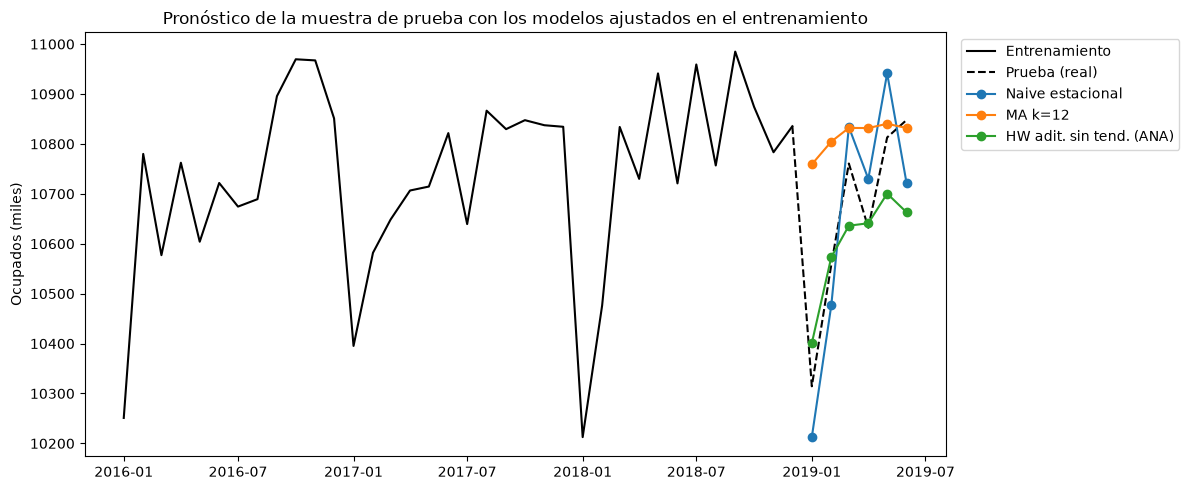

In [16]:
# Cada modelo se ajusta con todo el entrenamiento y pronostica los 6 meses de prueba
modelo_elegido = "HW adit. sin tend. (ANA)"

modelos_prueba = {
    "Naive estacional": pronostico_naive_estacional,
    "MA k=12": lambda serie_ajuste, h: pronostico_promedio_movil(serie_ajuste, h, k=12),
    modelo_elegido: lambda serie_ajuste, h: ajustar_ets(serie_ajuste, configuraciones_ets[modelo_elegido]).forecast(h).values,
}

pronosticos_prueba = pd.DataFrame(
    {nombre: funcion(train, horizonte) for nombre, funcion in modelos_prueba.items()},
    index=test.index,
)

resultados_prueba = pd.DataFrame({
    "RMSE": {nombre: np.sqrt(mean_squared_error(test, pronosticos_prueba[nombre])) for nombre in pronosticos_prueba},
    "MAPE (%)": {nombre: 100 * mean_absolute_percentage_error(test, pronosticos_prueba[nombre]) for nombre in pronosticos_prueba},
})
print("Error en la muestra de prueba (2019-01 a 2019-06):")
print(resultados_prueba.round(2))

print("\nValores reales y pronósticos (miles):")
print(pd.concat([test.rename("Real"), pronosticos_prueba], axis=1).round(1).to_string())

# Gráfica: últimos 3 años del entrenamiento, prueba y pronósticos
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.loc["2016":], color="black", label="Entrenamiento")
ax.plot(pd.concat([train.iloc[-1:], test]), color="black", linestyle="--", label="Prueba (real)")
for nombre in pronosticos_prueba:
    ax.plot(pronosticos_prueba[nombre], marker="o", label=nombre)
ax.set_title("Pronóstico de la muestra de prueba con los modelos ajustados en el entrenamiento")
ax.set_ylabel("Ocupados (miles)")
# Leyenda fuera del área de datos para no tapar la serie
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Resultados en la muestra de prueba

| Modelo | RMSE (miles) | MAPE (%) |
|---|---|---|
| Naive estacional | 103.75 | 0.95 |
| HW aditivo sin tendencia (ANA) | 108.16 | 0.83 |
| MA k=12 | 225.31 | 1.60 |

En la prueba, el modelo elegido y el naive estacional obtienen un desempeño muy similar: el naive estacional tiene un RMSE 4.4 mil menor, mientras que el modelo ANA tiene un MAPE menor. La diferencia se explica por la forma de los errores mensuales. El modelo ANA acierta casi exactamente en febrero y abril (errores de 15.2 y 9.0 mil), pero subestima marzo, mayo y junio, con un error de 185.1 mil en junio que el RMSE penaliza con fuerza al elevarlo al cuadrado. El naive estacional, en cambio, se equivoca entre 73 y 128 mil en todos los meses. En promedio absoluto, el error del modelo ANA es menor (88.8 frente a 101.7 mil).

La subestimación de los últimos meses ocurre porque en 2019 el nivel de la serie subió hasta cerca de 10 850 mil, mientras que el modelo ANA, al no tener tendencia, pronostica alrededor de 10 640 a 10 700 mil. El promedio móvil de 12 meses vuelve a tener el peor desempeño, porque pronostica un valor casi constante y no reproduce la caída de enero (error de 444.7 mil).

El RMSE del modelo ANA en la prueba (108.16 mil) es menor que su promedio en la validación (122.02 mil) y está dentro del rango observado entre cortes (67.8 a 152.8 mil), lo que es coherente con el error estimado en la validación. Con solo 6 meses, la diferencia frente al naive estacional no permite concluir que uno de los dos sea mejor, y la elección no se modifica a partir de la prueba para no usar esta información en la selección del modelo.

## 9. Pronóstico de los próximos 6 meses

Para pronosticar julio a diciembre de 2019 se vuelve a ajustar el modelo elegido con toda la serie disponible (enero de 2001 a junio de 2019), de modo que el pronóstico parta de la información más reciente, incluidos los meses de prueba. Los parámetros de suavización ($\alpha$ y $\gamma$) se mantienen fijos en los valores estimados con el entrenamiento, que son los del modelo validado y evaluado en la prueba, y solo se vuelven a estimar los estados iniciales (nivel y efectos estacionales). El pronóstico se acompaña de intervalos de predicción del 95 %, que indican el rango en que se espera que esté cada valor futuro. Para la configuración ANA, statsmodels calcula estos intervalos con una fórmula exacta y no por simulación.

Parámetros fijos: {'smoothing_level': 0.5914, 'smoothing_seasonal': 0.0}
Método de cálculo de los intervalos: exact

Pronóstico de ocupados (miles):
            Pronóstico  Límite inferior 95 %  Límite superior 95 %
2019-07-01     10878.3               10649.4               11107.2
2019-08-01     10851.8               10585.8               11117.7
2019-09-01     10911.6               10613.2               11210.0
2019-10-01     11021.2               10693.5               11348.9
2019-11-01     11031.7               10677.1               11386.2
2019-12-01     10938.8               10559.3               11318.3


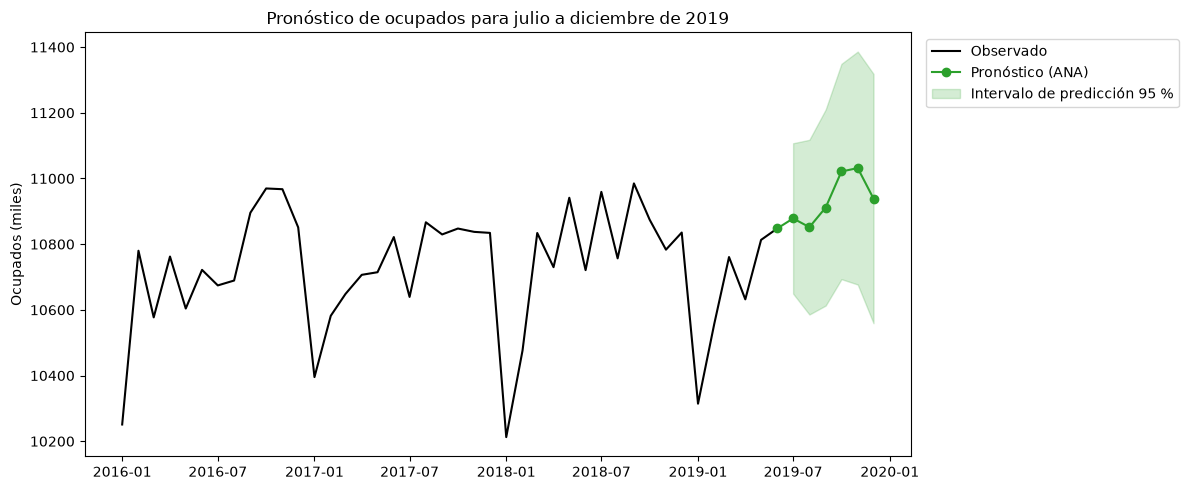

In [17]:
# Parámetros de suavización del modelo elegido, estimados con el entrenamiento
ajuste_entrenamiento = ajustar_ets(train, configuraciones_ets[modelo_elegido])
parametros_entrenamiento = pd.Series(np.asarray(ajuste_entrenamiento.params), index=ajuste_entrenamiento.param_names)
parametros_fijos = {
    "smoothing_level": float(parametros_entrenamiento["smoothing_level"]),
    "smoothing_seasonal": float(parametros_entrenamiento["smoothing_seasonal"]),
}
print("Parámetros fijos:", {nombre: round(valor, 4) for nombre, valor in parametros_fijos.items()})

# Reajuste con toda la serie (2001-01 a 2019-06): solo se estiman los estados iniciales
modelo_final = ETSModel(ocupados, seasonal_periods=12, **configuraciones_ets[modelo_elegido])
ajuste_final = modelo_final.fit_constrained(parametros_fijos)

# Pronóstico de 2019-07 a 2019-12 con intervalo de predicción del 95 %
prediccion_final = ajuste_final.get_prediction(start=len(ocupados), end=len(ocupados) + horizonte - 1)
pronostico_final = prediccion_final.summary_frame(alpha=0.05)
pronostico_final.columns = ["Pronóstico", "Límite inferior 95 %", "Límite superior 95 %"]
print("Método de cálculo de los intervalos:", prediccion_final.method)
print("\nPronóstico de ocupados (miles):")
print(pronostico_final.round(1).to_string())

# Gráfica: serie desde 2016, pronóstico e intervalo de predicción
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(ocupados.loc["2016":], color="black", label="Observado")
ax.plot(pd.concat([ocupados.iloc[-1:], pronostico_final["Pronóstico"]]), color="tab:green",
        marker="o", label="Pronóstico (ANA)")
ax.fill_between(pronostico_final.index, pronostico_final["Límite inferior 95 %"],
                pronostico_final["Límite superior 95 %"], color="tab:green", alpha=0.2,
                label="Intervalo de predicción 95 %")
ax.set_title("Pronóstico de ocupados para julio a diciembre de 2019")
ax.set_ylabel("Ocupados (miles)")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Pronóstico de julio a diciembre de 2019

| Mes | Pronóstico (miles) | Intervalo de predicción 95 % | Ancho del intervalo |
|---|---|---|---|
| 2019-07 | 10 878.3 | 10 649.4 – 11 107.2 | 457.8 |
| 2019-08 | 10 851.8 | 10 585.8 – 11 117.7 | 531.9 |
| 2019-09 | 10 911.6 | 10 613.2 – 11 210.0 | 596.8 |
| 2019-10 | 11 021.2 | 10 693.5 – 11 348.9 | 655.4 |
| 2019-11 | 11 031.7 | 10 677.1 – 11 386.2 | 709.1 |
| 2019-12 | 10 938.8 | 10 559.3 – 11 318.3 | 759.0 |

El pronóstico parte de un nivel cercano a 10 850 mil personas, similar al valor de junio de 2019 (10 848.0 mil), y sobre él aplica el patrón estacional estimado. Como $\gamma = 0$, ese patrón es fijo, y la forma del pronóstico reproduce los efectos estacionales de la sección 4: un aumento en octubre y noviembre, que son los meses más altos del año, y una reducción en diciembre. Por ejemplo, el aumento pronosticado entre agosto y octubre (169.4 mil) es casi igual a la diferencia entre los efectos estacionales de esos meses en la descomposición aditiva (171.7 mil). El valor pronosticado para noviembre (11 031.7 mil) quedaría cerca del máximo de la serie (11 037.2 mil).

Los intervalos de predicción se calculan con la fórmula exacta del modelo ANA y se ensanchan a medida que aumenta el horizonte, desde ±228.9 mil en julio hasta ±379.5 mil en diciembre. En este modelo, la desviación del error a $h$ meses es $\sigma\sqrt{1 + (h-1)\alpha^2}$; con $\alpha = 0.59$, la de diciembre es cerca de 1.66 veces la de julio. Como el nivel se actualiza con rapidez, su incertidumbre se acumula con cada mes pronosticado. En diciembre, el intervalo va de 10 559.3 a 11 318.3 mil, un rango de cerca de 7 % del valor pronosticado.

## 10. Conclusiones y limitaciones

### Conclusiones

- La serie de ocupados de las 13 ciudades tiene una tendencia creciente hasta 2015, que se aplana entre 2016 y 2018, y una estacionalidad anual marcada, con una caída en enero y un máximo en octubre y noviembre. En el periodo de validación, la estacionalidad fue el componente que más mejoró el pronóstico a 6 meses: agregarla a la suavización exponencial simple redujo el RMSE cerca de 40 %, mientras que agregar una tendencia lineal lo empeoró, y todos los modelos que no la incluyen (promedios móviles, SES y Holt) tuvieron errores mayores que el naive estacional.
- Los promedios móviles no son adecuados para esta serie. Con ventanas cortas, el pronóstico arrastra el nivel de meses con efectos estacionales distintos a los del periodo pronosticado, y con la ventana de 12 meses el pronóstico es casi constante. El mejor promedio móvil (12 meses) tuvo un RMSE de 181.58 mil en la validación y de 225.31 mil en la prueba.
- Entre los modelos de suavización exponencial, el Holt-Winters con estacionalidad aditiva y sin tendencia (ANA) obtuvo el menor error en la validación (RMSE de 122.02 mil y MAPE de 0.98 %), superó al naive estacional en 4 de los 6 cortes y es una de las configuraciones más simples. La tendencia lineal sin amortiguar empeoró el pronóstico en todas las configuraciones, porque extendía hacia 2016-2018 el crecimiento de los años anteriores.
- Aunque la descomposición sugería una estacionalidad multiplicativa, en la validación la aditiva tuvo menor error. En el periodo evaluado el nivel de la serie fue casi constante, por lo que la diferencia entre ambos supuestos fue pequeña.
- En la prueba (enero a junio de 2019), el modelo ANA tuvo un RMSE de 108.16 mil y un MAPE de 0.83 %, consistente con lo estimado en la validación, y un desempeño similar al del naive estacional (103.75 mil y 0.95 %).
- Para julio a diciembre de 2019 se pronostica un número de ocupados entre 10 852 y 11 032 mil, con un máximo en octubre y noviembre, e intervalos de predicción del 95 % que se amplían de ±229 mil en julio a ±380 mil en diciembre.

### Limitaciones

- **Periodo de validación.** Los 6 cortes corresponden a 2016-2018, un periodo de tendencia casi plana. Este contexto favoreció a los modelos sin tendencia, y la elección podría ser distinta si la serie vuelve a crecer o a caer con fuerza.
- **Sin tendencia.** El modelo elegido no anticipa cambios en el nivel. En la prueba subestimó los meses de marzo a junio de 2019, cuando la serie subió.
- **Estacionalidad fija.** El parámetro $\gamma$ estimado fue 0, por lo que el modelo mantiene el mismo patrón estacional para todos los años, aunque en la sección 4 la caída de enero fue en promedio mayor en los últimos años. Además, los parámetros se estiman con los errores de pronóstico a un mes, mientras que el objetivo del ejercicio es pronosticar a 6 meses.
- **Ventaja pequeña frente a la referencia.** La mejora frente al naive estacional fue de cerca de 8.5 % en la validación, y en la prueba ambos modelos tuvieron un desempeño similar. Con 6 cortes y 6 meses de prueba no es posible afirmar que la diferencia sea significativa.
- **Intervalos de predicción.** Los intervalos suponen errores normales con varianza constante y no incluyen la incertidumbre de la estimación de los parámetros, por lo que pueden ser más estrechos de lo que deberían.
- **Modelo univariado.** El pronóstico solo usa la historia de la serie, por lo que no puede anticipar cambios causados por factores externos, como cambios en la actividad económica o en la política laboral.
- **Nivel de agregación.** El pronóstico corresponde al total de las 13 ciudades y no permite sacar conclusiones sobre el empleo de cada ciudad.